# Étape 10 : ERC calculé sur nos propres facteurs

Test de robustesse de l'étape 9. Une seule chose change : les volatilités et corrélations utilisées pour les poids ERC viennent des **facteurs reconstruits sur le S&P 500** (étape 8.4), et non des facteurs de Fama et French. Tout le reste est identique : score, sélection, zone tampon, pondération, plafond, frais.

## 1. Données et outils de l'étape 9

In [1]:
import io
import zipfile
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy.optimize import minimize
from scipy.stats import norm
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

warnings.filterwarnings("ignore", category=FutureWarning)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
FIG = ROOT / "docs" / "figures"

pd.set_option("display.precision", 3)
pd.set_option("display.width", 140)

In [2]:
base = pd.read_csv(ROOT / "data" / "processed" / "zscores_sp500_mensuels.csv.gz")
base["mois"] = pd.PeriodIndex(base["mois"], freq="M")
base = base.set_index(["mois", "ticker"]).sort_index()

ajustes = pd.read_csv(RAW / "sp500_cours_ajustes_mensuels.csv", index_col=0)
ajustes.index = pd.PeriodIndex(ajustes.index.astype(str).str[:7], freq="M")
rendements = ajustes.pct_change(fill_method=None)


def lire_bloc_mensuel(chemin_zip):
    with zipfile.ZipFile(chemin_zip) as z:
        texte = z.read(z.namelist()[0]).decode("latin-1")
    lignes = texte.splitlines()
    debut = next(i for i, l in enumerate(lignes) if l.startswith(","))
    bloc = [lignes[debut]]
    for l in lignes[debut + 1:]:
        if not l.strip() or not l.strip()[0].isdigit():
            break
        bloc.append(l)
    df = pd.read_csv(io.StringIO("\n".join(bloc)), index_col=0)
    df.columns = df.columns.str.strip()
    df.index = pd.PeriodIndex(df.index.astype(str), freq="M")
    return df.astype(float) / 100


facteurs = lire_bloc_mensuel(RAW / "F-F_Research_Data_5_Factors_2x3_CSV.zip").join(
    lire_bloc_mensuel(RAW / "F-F_Momentum_Factor_CSV.zip"), how="inner")
rf = facteurs["RF"]

etf = pd.read_csv(RAW / "cours_mensuels.csv", index_col=0)[["SPY", "RSP"]]
etf.index = pd.PeriodIndex(etf.index, freq="M")
rend_etf = etf.pct_change()

mois = base.index.get_level_values("mois").unique()
print(f"z-scores : {mois[0]} à {mois[-1]}, {len(mois)} mois")

z-scores : 2012-02 à 2026-08, 175 mois


In [3]:
STYLES = {"z_smb": "SMB", "z_hml": "HML", "z_rmw": "RMW", "z_cma": "CMA", "z_mom": "Mom"}
Z = base[list(STYLES)]

In [4]:
def poids_erc(cov):
    # Spinu (2013) : le minimum de 1/2 y'Σy - (1/n) Σ log(y) donne des contributions au risque égales.
    n = len(cov)
    y0 = 1 / np.sqrt(np.diag(cov))
    y = minimize(lambda y: 0.5 * y @ cov @ y - np.log(y).sum() / n, y0,
                 jac=lambda y: cov @ y - 1 / (n * y), bounds=[(1e-10, None)] * n, method="L-BFGS-B").x
    return y / y.sum()


def contributions(w, cov):
    rc = w * (cov @ w)
    return rc / rc.sum()


poids = {}
for m in mois:
    histo = facteurs.loc[:m, list(STYLES.values())].iloc[-60:]
    poids[m] = poids_erc(histo.cov().values)
poids = pd.DataFrame(poids, index=list(STYLES.values())).T

# Contrôle : contributions au risque au dernier mois
cov_fin = facteurs.loc[:mois[-1], list(STYLES.values())].iloc[-60:].cov().values
print("Contributions au risque (dernier mois) :", np.round(contributions(poids.iloc[-1].values, cov_fin), 3))
print("\nPoids ERC des facteurs dans le score, résumé sur la période :")
poids.describe().loc[["mean", "min", "max"]].round(2)

Contributions au risque (dernier mois) : [0.2 0.2 0.2 0.2 0.2]

Poids ERC des facteurs dans le score, résumé sur la période :


,SMB,HML,RMW,CMA,Mom
mean,0.23,0.13,0.30,0.18,0.17
min,0.17,0.08,0.25,0.12,0.08
max,0.32,0.22,0.36,0.23,0.22


In [5]:
def score_final(w):
    # w : DataFrame (mois x facteurs) de poids
    wl = w.reindex(Z.index.get_level_values("mois")).set_axis(Z.index)
    wl.columns = list(STYLES)
    s = (Z.fillna(0) * wl).sum(axis=1)[Z.notna().sum(axis=1) >= 3]
    return s.groupby(level="mois").transform(lambda x: (x - x.mean()) / x.std())


egal = pd.DataFrame(0.2, index=mois, columns=list(STYLES.values()))
scores = pd.DataFrame({"score_equipondere": score_final(egal), "score_erc": score_final(poids)})
scores.to_csv(ROOT / "data" / "processed" / "scores_finaux_sp500.csv.gz", float_format="%.5g")

In [6]:
capi = base["capitalisation"]
PLAFOND = 0.10


def plafonner(w, plafond=PLAFOND):
    # Aucune action au-dessus du plafond ; l'excédent est redistribué aux autres, au prorata.
    w = w / w.sum()
    while (w > plafond + 1e-12).any():
        trop = w > plafond
        excedent = (w[trop] - plafond).sum()
        w[trop] = plafond
        w[~trop] += excedent * w[~trop] / w[~trop].sum()
    return w


def poids_cibles(score, seuil=0.30, tampon=0.40, ponderation="capi_score"):
    cibles, tenus = {}, set()
    for m in score.index.get_level_values("mois").unique()[:-1]:
        s = score.xs(m).dropna()
        c = capi.xs(m).reindex(s.index).dropna()
        s = s[c.index]
        rang = s.rank(ascending=False, pct=True)
        selection = set(rang[rang <= seuil].index)
        if tampon:
            selection |= set(rang[rang <= tampon].index) & tenus
        selection = sorted(selection)
        tenus = set(selection)
        if ponderation == "egale":
            w = pd.Series(1.0, index=selection)
        elif ponderation == "capi":
            w = c[selection]
        else:
            w = c[selection] * (1 + s[selection]).clip(lower=0)
        cibles[m] = plafonner(w)
    return cibles

In [7]:
def backtest(cibles, frais=0.0010):
    lignes, derive, manquants = {}, pd.Series(dtype=float), 0
    for m, w in cibles.items():
        rotation = w.subtract(derive, fill_value=0).abs().sum()
        r = rendements.loc[m + 1].reindex(w.index)
        manquants += int(r.isna().sum())
        r = r.fillna(0)
        brut = float((w * r).sum())
        lignes[m + 1] = {"brut": brut, "rotation": rotation, "net": brut - frais * rotation}
        derive = w * (1 + r)
        derive = derive / derive.sum()
    sortie = pd.DataFrame(lignes).T
    sortie.attrs["manquants"] = manquants
    return sortie


def univers_capi():
    return {m: capi.xs(m).dropna() / capi.xs(m).dropna().sum() for m in mois[:-1]}

In [8]:
def test_moyenne(a):
    m = sm.OLS(a.values, np.ones(len(a))).fit(cov_type="HAC", cov_kwds={"maxlags": 6})
    return m.params[0], m.tvalues[0], m.pvalues[0]


def indices_bootstrap(n, bloc_moyen, rng):
    idx = np.empty(n, dtype=int)
    idx[0] = rng.integers(n)
    for i in range(1, n):
        idx[i] = rng.integers(n) if rng.random() < 1 / bloc_moyen else (idx[i - 1] + 1) % n
    return idx


def sharpe(x, r_f):
    e = x - r_f
    return e.mean() / e.std() * np.sqrt(12)


def bootstrap(strat, bench, n_tirages=5000, bloc_moyen=6, graine=0):
    rng = np.random.default_rng(graine)
    s, b, f = strat.values, bench.values, rf.reindex(strat.index).values
    actif, d_sharpe = [], []
    for _ in range(n_tirages):
        i = indices_bootstrap(len(s), bloc_moyen, rng)
        actif.append((s[i] - b[i]).mean() * 12)
        d_sharpe.append(sharpe(s[i], f[i]) - sharpe(b[i], f[i]))
    return np.percentile(actif, [2.5, 97.5]), np.percentile(d_sharpe, [2.5, 97.5])

## 2. Les facteurs reconstruits sur notre univers

Comme à l'étape 8.4 : chaque fin de mois, on achète les 30 % d'actions au z-score le plus élevé et on vend les 30 % au plus bas, chaque jambe pondérée par la capitalisation. Le rendement du facteur est celui du mois suivant.

In [9]:
def facteur_reconstruit(col):
    d = base[[col, "capitalisation"]].dropna()
    sortie = {}
    for m in mois[:-1]:
        g = d.xs(m)
        r = rendements.loc[m + 1].reindex(g.index)
        g = g[r.notna()]
        r = r[g.index]
        bas, haut = g[col].quantile([0.3, 0.7])
        h, b = g[col] >= haut, g[col] <= bas
        sortie[m + 1] = (np.average(r[h], weights=g.loc[h, "capitalisation"])
                         - np.average(r[b], weights=g.loc[b, "capitalisation"]))
    return pd.Series(sortie)


maison = pd.DataFrame({STYLES[c]: facteur_reconstruit(c) for c in STYLES})
commun = maison.index.intersection(facteurs.index)
comparaison = pd.DataFrame({
    "volatilité French": facteurs.loc[commun, maison.columns].std() * np.sqrt(12),
    "volatilité reconstruit": maison.loc[commun].std() * np.sqrt(12),
    "corrélation": [maison.loc[commun, k].corr(facteurs.loc[commun, k]) for k in maison.columns],
})
print(f"Facteurs reconstruits : {maison.index[0]} à {maison.index[-1]}")
comparaison.style.format({"volatilité French": "{:.1%}", "volatilité reconstruit": "{:.1%}", "corrélation": "{:.2f}"})

Facteurs reconstruits : 2012-03 à 2026-08


,volatilité French,volatilité reconstruit,corrélation
SMB,9.5%,9.9%,0.63
HML,11.7%,15.2%,0.87
RMW,8.1%,8.7%,0.53
CMA,7.7%,10.0%,0.68
Mom,13.2%,14.5%,0.88


In [10]:
# Corrélations entre facteurs, sur la même période
pd.concat({"French": facteurs.loc[commun, maison.columns].corr(), "reconstruits": maison.loc[commun].corr()}, axis=1).round(2)

French                         reconstruits                        
       SMB   HML   RMW   CMA   Mom          SMB   HML   RMW   CMA   Mom
SMB   1.00  0.33 -0.30  0.05 -0.33         1.00  0.78 -0.38  0.50 -0.57
HML   0.33  1.00  0.14  0.63 -0.29         0.78  1.00 -0.48  0.61 -0.54
RMW  -0.30  0.14  1.00  0.23 -0.14        -0.38 -0.48  1.00 -0.28  0.02
CMA   0.05  0.63  0.23  1.00 -0.03         0.50  0.61 -0.28  1.00 -0.29
Mom  -0.33 -0.29 -0.14 -0.03  1.00        -0.57 -0.54  0.02 -0.29  1.00

## 3. Les poids ERC sur nos facteurs

Même règle qu'à l'étape 9 : covariance des 60 derniers mois. Les facteurs reconstruits commencent en mars 2012. Les premiers poids sont donc disponibles fin février 2017, et la comparaison porte sur **mars 2017 à août 2026**.

In [11]:
poids_maison = {}
for m in mois:
    histo = maison.loc[:m].iloc[-60:]
    if len(histo) == 60:
        poids_maison[m] = poids_erc(histo.cov().values)
poids_maison = pd.DataFrame(poids_maison, index=list(STYLES.values())).T
DEBUT = poids_maison.index[0]
print("Premiers poids ERC sur facteurs reconstruits :", DEBUT)

moyennes = pd.DataFrame({"ERC French": poids.loc[DEBUT:].mean(), "ERC reconstruit": poids_maison.mean()})
moyennes.style.format("{:.0%}")

Premiers poids ERC sur facteurs reconstruits : 2017-02


,ERC French,ERC reconstruit
SMB,24%,19%
HML,11%,15%
RMW,29%,32%
CMA,16%,13%
Mom,20%,21%


In [12]:
scores["score_erc_reconstruit"] = score_final(poids_maison)
sur_periode = scores[scores.index.get_level_values("mois") >= DEBUT]
print("Corrélation entre les scores (même période) :")
sur_periode.corr().round(2)

Corrélation entre les scores (même période) :


,score_equipondere,score_erc,score_erc_reconstruit
score_equipondere,1.00,0.92,0.90
score_erc,0.92,1.00,0.96
score_erc_reconstruit,0.90,0.96,1.00


## 4. Backtest complet, avec frais

Mêmes règles qu'à l'étape 9 : 30 % meilleurs scores, zone tampon à 40 %, poids capitalisation × (1 + score), plafond de 10 % par action, 0,10 % de frais par dollar échangé. Benchmark principal : l'univers pondéré par la capitalisation.

In [13]:
def sur(score):
    return score[score.index.get_level_values("mois") >= DEBUT]


strategies = {
    "ERC French (étape 9)": backtest(poids_cibles(sur(scores["score_erc"]))),
    "ERC reconstruit": backtest(poids_cibles(sur(scores["score_erc_reconstruit"]))),
    "Score équipondéré": backtest(poids_cibles(sur(scores["score_equipondere"]))),
}
univers = {m: capi.xs(m).dropna() / capi.xs(m).dropna().sum() for m in mois[:-1] if m >= DEBUT}
reference = backtest(univers)
periode = reference.index
print(f"Période : {periode[0]} à {periode[-1]}, {len(periode)} mois")


def indicateurs(r):
    r = r.reindex(periode)
    exces = r - rf.reindex(periode)
    valeur = (1 + r).cumprod()
    return pd.Series({
        "rendement annuel": valeur.iloc[-1] ** (12 / len(r)) - 1,
        "volatilité": r.std() * np.sqrt(12),
        "Sharpe": exces.mean() / exces.std() * np.sqrt(12),
        "perte maximale": (valeur / valeur.cummax() - 1).min(),
    })


series = {k: v["net"] for k, v in strategies.items()}
series["Univers (capitalisation)"] = reference["net"]
series["SPY"] = rend_etf["SPY"]
resultats = pd.DataFrame({k: indicateurs(v) for k, v in series.items()}).T
resultats["rotation annuelle"] = [strategies[k]["rotation"].iloc[1:].mean() * 12 if k in strategies else np.nan
                                  for k in resultats.index]
resultats.style.format({"rendement annuel": "{:.1%}", "volatilité": "{:.1%}", "Sharpe": "{:.2f}",
                        "perte maximale": "{:.1%}", "rotation annuelle": "{:.0%}"}, na_rep="")

Période : 2017-03 à 2026-08, 114 mois


,rendement annuel,volatilité,Sharpe,perte maximale,rotation annuelle
ERC French (étape 9),13.7%,17.4%,0.69,-23.2%,312%
ERC reconstruit,14.0%,17.0%,0.72,-24.9%,308%
Score équipondéré,14.9%,17.8%,0.74,-28.2%,318%
Univers (capitalisation),15.6%,15.7%,0.85,-23.6%,
SPY,15.0%,15.6%,0.82,-23.9%,


In [14]:
lignes = []
for nom, bench_nom in [("ERC reconstruit", "ERC French (étape 9)"), ("ERC reconstruit", "Univers (capitalisation)"),
                       ("ERC French (étape 9)", "Univers (capitalisation)")]:
    s = strategies[nom]["net"]
    b = series[bench_nom].reindex(periode)
    a = s - b
    moy, t, p = test_moyenne(a)
    ic_actif, ic_sharpe = bootstrap(s, b)
    lignes.append({"stratégie": nom, "benchmark": bench_nom, "rendement actif annuel": 12 * moy,
                   "écart de suivi": a.std() * np.sqrt(12), "IR": a.mean() / a.std() * np.sqrt(12),
                   "t (Newey-West)": t, "p-valeur": p,
                   "IC 95 % rendement actif": f"[{ic_actif[0]:+.1%} ; {ic_actif[1]:+.1%}]",
                   "écart de Sharpe": sharpe(s, rf.reindex(periode)) - sharpe(b, rf.reindex(periode)),
                   "IC 95 % écart de Sharpe": f"[{ic_sharpe[0]:+.2f} ; {ic_sharpe[1]:+.2f}]"})
pd.DataFrame(lignes).set_index(["stratégie", "benchmark"]).style.format(
    {"rendement actif annuel": "{:+.2%}", "écart de suivi": "{:.1%}", "IR": "{:+.2f}", "t (Newey-West)": "{:+.2f}",
     "p-valeur": "{:.2f}", "écart de Sharpe": "{:+.2f}"})

In [15]:
# Sensibilité aux frais : rendement actif annuel contre l'univers
niveaux = [0, 10, 25, 50]
pd.DataFrame({
    nom: [12 * (bt["brut"] - pb / 1e4 * bt["rotation"] - reference["brut"] + pb / 1e4 * reference["rotation"]).mean()
          for pb in niveaux]
    for nom, bt in strategies.items()}, index=pd.Index(niveaux, name="frais (points de base)")).style.format("{:+.2%}")

,ERC French (étape 9),ERC reconstruit,Score équipondéré
frais (points de base),,,
0,-1.13%,-0.92%,+0.10%
10,-1.43%,-1.22%,-0.21%
25,-1.88%,-1.66%,-0.67%
50,-2.62%,-2.40%,-1.43%


## 5. Graphique

In [16]:
SURFACE, TEXTE, TEXTE2, GRILLE = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLEU, ORANGE, AQUA, JAUNE, MAGENTA, VERT = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"
GRIS = "#8d8c88"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "DejaVu Sans", "font.size": 10,
    "text.color": TEXTE, "axes.labelcolor": TEXTE2, "xtick.color": TEXTE2, "ytick.color": TEXTE2,
    "axes.edgecolor": GRILLE, "axes.grid": True, "grid.color": GRILLE, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False,
})


def sauver(fig, nom):
    fig.savefig(FIG / nom, dpi=200, bbox_inches="tight")


def virgule(fmt):
    return plt.FuncFormatter(lambda v, _: fmt.format(v).replace(".", ",").replace("-", "−"))


COULEURS = {"Score équipondéré": BLEU, "Score ERC": ORANGE, "Univers (capitalisation)": TEXTE2, "SPY": GRIS}

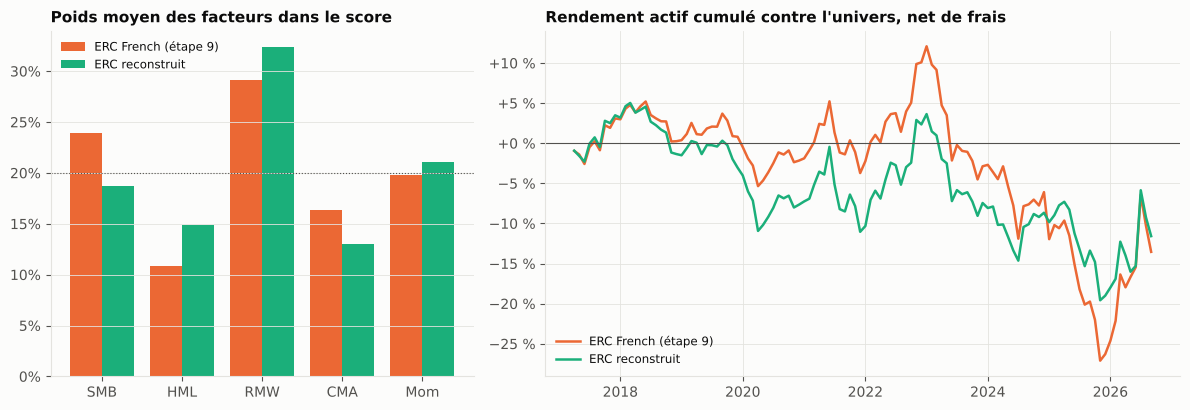

In [17]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [2, 3]})
x = np.arange(len(moyennes))
ax1.bar(x - 0.2, moyennes["ERC French"], 0.4, color=ORANGE, label="ERC French (étape 9)")
ax1.bar(x + 0.2, moyennes["ERC reconstruit"], 0.4, color=AQUA, label="ERC reconstruit")
ax1.axhline(0.2, color=TEXTE2, lw=0.8, ls=":")
ax1.set_xticks(x, moyennes.index)
ax1.yaxis.set_major_formatter(virgule("{:.0%}"))
ax1.set_title("Poids moyen des facteurs dans le score")
ax1.legend(loc="upper left", fontsize=8.5)
ax1.grid(axis="x", visible=False)

d = periode.to_timestamp(how="end")
for nom, couleur in [("ERC French (étape 9)", ORANGE), ("ERC reconstruit", AQUA)]:
    a = strategies[nom]["net"] - reference["net"]
    ax2.plot(d, 100 * a.cumsum(), color=couleur, lw=1.8, label=nom)
ax2.axhline(0, color=TEXTE2, lw=0.8)
ax2.yaxis.set_major_formatter(virgule("{:+.0f} %"))
ax2.xaxis.set_major_locator(mdates.YearLocator(2))
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax2.set_title("Rendement actif cumulé contre l'univers, net de frais")
ax2.legend(loc="lower left", fontsize=8.5)
fig.tight_layout()
sauver(fig, "amelioration_erc_reconstruit.png")
plt.show()